# Lab 10 — Fine-tuning BERT for Language Identification (23 Indian languages)

**Task** (Lab 10, item 2): fine-tune a pretrained BERT on the language-identification dataset built in
Lab 1 (`Lab1/data/{train,val,test}.csv`, 18,400 / 2,300 / 2,300 sentences, 23 languages), and compare it
with the models from Lab 6 — logistic regression, MLP (1 and 2 hidden layers), LSTM, GRU, and FastText
supervised — on the same test set and the same hand-computed macro-F1.

**Model:** `google/muril-base-cased` — a BERT-base architecture pretrained on Indian-language text (17
Indian languages, including several of this dataset's). It is a base-size model, so it runs on the local
4 GB GPU.

**Choices that differ from a default fine-tune, and why**
- **Gradient checkpointing on.** Activations for a batch of 16 × 128 tokens do not fit next to the optimiser state
  on a 4 GB GPU. Checkpointing recomputes activations in the backward pass, costing about a third more time.
- **Word-embedding matrix frozen.** MuRIL's 197k-token embedding table is about 150M of its ~237M
  parameters. Training it with AdamW needs roughly 4 GB of optimiser state, which does not fit on this
  GPU. Everything else (all 12 transformer layers, the pooler, and the classifier head) is trained.
- **Model selection on validation macro-F1**, then one evaluation on the test set. The test set is not
  used to pick the epoch.
- **Macro-F1 is computed by hand** from a confusion matrix, as in Lab 6. No `sklearn.metrics` is used.

## 0. Setup

In [1]:
import json, os, random, time
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup
import matplotlib.pyplot as plt

SMOKE = os.environ.get("LAB10_SMOKE", "0") == "1"    # tiny end-to-end check when set
MODEL_ID = "google/muril-base-cased"
DATA_DIR = "../Lab1/data"
OUT = "data/smoke" if SMOKE else "data"
WEIGHTS = os.path.expanduser("~/.cache/lab10_muril/smoke_best.pt" if SMOKE else "~/.cache/lab10_muril/best.pt")
MAX_LEN = 128
BATCH = 16
EPOCHS = 1 if SMOKE else 3
LR = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_FRAC = 0.1
SEED = 42

os.makedirs(OUT, exist_ok=True)
os.makedirs(os.path.dirname(WEIGHTS), exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| SMOKE:", SMOKE, "| output dir:", OUT)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB")


device: cuda | SMOKE: False | output dir: data
GPU: NVIDIA GeForce RTX 3050 Laptop GPU 3.7 GiB


## 1. Data: the Lab 1 splits and the 23 labels

The labels come from `languages.json`, the same order Lab 6 used. The splits are the Lab 1 files unchanged.

In [2]:
labels = json.load(open(f"{DATA_DIR}/languages.json", encoding="utf-8"))
label2id = {l: i for i, l in enumerate(labels)}
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
if SMOKE:
    train_df, val_df, test_df = train_df.sample(300, random_state=SEED), val_df.head(200), test_df.head(200)
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}  classes={len(labels)}")
pd.concat([train_df.label.value_counts().rename("train"), test_df.label.value_counts().rename("test")], axis=1).head(3)


train=18400  val=2300  test=2300  classes=23


,train,test
label,,
asm_Beng,800,100
mni_Mtei,800,100
khasi,800,100


## 2. Tokenizer diagnostics

Before training: how long are the sentences in tokens (to choose `max_length`), and how often does MuRIL's
vocabulary fail on each language (`[UNK]` rate)? A high `[UNK]` rate means the model cannot see those
characters at all, so it is a ceiling on that language's F1 that no training can remove.

In [3]:
tok = AutoTokenizer.from_pretrained(MODEL_ID)

lens = np.array([len(x) for x in tok(train_df.text.astype(str).tolist(), add_special_tokens=True)["input_ids"]])
print(f"token length (train): median={np.median(lens):.0f}  p95={np.percentile(lens, 95):.0f}  p99={np.percentile(lens, 99):.0f}")
print(f"share of train sentences longer than MAX_LEN={MAX_LEN}: {100 * (lens > MAX_LEN).mean():.2f}%")

unk_rows = []
for lab in labels:
    sub = test_df[test_df.label == lab].text.astype(str).tolist()
    if not sub:
        continue
    ids = tok(sub, add_special_tokens=False)["input_ids"]
    n = sum(len(x) for x in ids)
    u = sum(t == tok.unk_token_id for x in ids for t in x)
    unk_rows.append({"label": lab, "test_tokens": n, "unk_pct": round(100 * u / max(n, 1), 2)})
unk_df = pd.DataFrame(unk_rows).sort_values("unk_pct", ascending=False)
unk_df.to_csv(f"{OUT}/unk_rate_by_language.csv", index=False)
unk_df.head(8)


token length (train): median=21  p95=55  p99=81
share of train sentences longer than MAX_LEN=128: 0.02%


,label,test_tokens,unk_pct
18,santhali,1889,88.09
13,mni_Mtei,1898,83.14
17,san_Deva,1409,3.62
8,kas_Arab,3116,2.41
15,ory_Orya,1680,0.24
4,gom_Deva,1825,0.22
9,khasi,3374,0.18
21,tel_Telu,1828,0.16


## 3. Macro-F1, computed by hand

Same implementation as Lab 6: a confusion matrix, then per-class precision, recall and F1, then the
unweighted mean over all 23 classes. Nothing here imports `sklearn.metrics`.

In [4]:
def confusion_matrix(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=np.int64)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm


def macro_f1(y_true, y_pred, n_classes=len(labels)):
    cm = confusion_matrix(y_true, y_pred, n_classes)
    per_class, f1s = {}, []
    for i, lab in enumerate(labels):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        per_class[lab] = {"precision": float(precision), "recall": float(recall), "f1": float(f1),
                          "support": int(cm[i, :].sum())}
        f1s.append(f1)
    return float(np.mean(f1s)), per_class


def accuracy(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))


## 4. Fine-tuning

Standard BERT classification fine-tune: `[CLS]` pooled output → linear layer over 23 labels, cross-entropy
loss, AdamW with linear warm-up and decay, fp16 mixed precision, gradient clipping at 1.0. The model is
evaluated on validation macro-F1 after every epoch, and the best epoch's weights are kept.

The run is cache-aware: if the best weights and the results file already exist, training is skipped.

In [5]:
class LangDS(Dataset):
    def __init__(self, df):
        self.texts = df.text.astype(str).tolist()
        self.y = [label2id[l] for l in df.label]

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.texts[i], self.y[i]


def collate(batch):
    texts, ys = zip(*batch)
    enc = tok(list(texts), padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
    enc["labels"] = torch.tensor(ys)
    return enc


train_dl = DataLoader(LangDS(train_df), batch_size=BATCH, shuffle=True, collate_fn=collate,
                      generator=torch.Generator().manual_seed(SEED))
val_dl = DataLoader(LangDS(val_df), batch_size=64, shuffle=False, collate_fn=collate)
test_dl = DataLoader(LangDS(test_df), batch_size=64, shuffle=False, collate_fn=collate)


@torch.no_grad()
def predict(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for batch in loader:
        labels_t = batch.pop("labels")
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            logits = model(**batch).logits
        y_pred += logits.argmax(-1).cpu().tolist()
        y_true += labels_t.tolist()
    return y_true, y_pred


model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID, num_labels=len(labels)).to(device)
model.base_model.embeddings.word_embeddings.weight.requires_grad_(False)   # see the note at the top
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})   # fits the 4 GB GPU at batch 16 x 128 tokens
n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"parameters: total {n_total / 1e6:.1f}M, trainable {n_train / 1e6:.1f}M")

results_path = f"{OUT}/bert_results.json"
if os.path.exists(results_path) and os.path.exists(WEIGHTS):
    print("cached results and weights found; skipping training")
    history = json.load(open(results_path))["history"]
else:
    trainable = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(trainable, lr=LR, weight_decay=WEIGHT_DECAY)
    total_steps = EPOCHS * len(train_dl)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    history, best_f1 = [], -1.0
    for ep in range(1, EPOCHS + 1):
        model.train()
        t0, running, n_steps = time.time(), 0.0, 0
        for step, batch in enumerate(train_dl, 1):
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
                loss = model(**batch).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(trainable, 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            running += loss.item()
            n_steps += 1
            if step % 200 == 0:
                print(f"  epoch {ep} step {step}/{len(train_dl)}  loss {running / n_steps:.4f}")
        y_t, y_p = predict(model, val_dl)
        val_f1, _ = macro_f1(y_t, y_p)
        val_acc = accuracy(y_t, y_p)
        history.append({"epoch": ep, "train_loss": running / n_steps, "val_macro_f1": val_f1,
                        "val_accuracy": val_acc, "minutes": round((time.time() - t0) / 60, 1)})
        print(f"epoch {ep}: train loss {running / n_steps:.4f}  val macro-F1 {val_f1:.4f}  val acc {val_acc:.4f}")
        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), WEIGHTS)
            print("  saved best weights")


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/muril-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


parameters: total 237.6M, trainable 86.1M


  epoch 1 step 200/1150  loss 3.1263


  epoch 1 step 400/1150  loss 3.0458


  epoch 1 step 600/1150  loss 2.9037


  epoch 1 step 800/1150  loss 2.7226


... (13 outputs left out)

  epoch 3 step 800/1150  loss 0.3101


  epoch 3 step 1000/1150  loss 0.3008


epoch 3: train loss 0.2974  val macro-F1 0.9378  val acc 0.9383


  saved best weights


## 5. Test-set evaluation (best-validation checkpoint, evaluated once)

In [6]:
import gc
for _name in ("opt", "sched", "scaler"):
    globals().pop(_name, None)            # free optimiser state before reloading weights
gc.collect()
torch.cuda.empty_cache()
model.load_state_dict(torch.load(WEIGHTS, map_location="cpu"))
y_true, y_pred = predict(model, test_dl)
bert_f1, bert_per_class = macro_f1(y_true, y_pred)
bert_acc = accuracy(y_true, y_pred)
print(f"BERT (MuRIL, fine-tuned)  test macro-F1 = {bert_f1:.4f}   test accuracy = {bert_acc:.4f}")

pred_df = test_df.reset_index(drop=True).copy()
pred_df["pred"] = [labels[p] for p in y_pred]
pred_df["correct"] = pred_df["pred"] == pred_df["label"]
pred_df.to_csv(f"{OUT}/test_predictions.csv", index=False)

json.dump({"model": MODEL_ID, "history": history, "test_macro_f1": bert_f1, "test_accuracy": bert_acc,
           "per_class_test": bert_per_class, "max_len": MAX_LEN, "batch": BATCH, "epochs": EPOCHS, "lr": LR,
           "frozen": "word_embeddings"}, open(results_path, "w"), indent=2, ensure_ascii=False)


BERT (MuRIL, fine-tuned)  test macro-F1 = 0.9410   test accuracy = 0.9413


## 6. Comparison with the Lab 6 models

The Lab 6 numbers are read from `Lab6/data/lab6_results.json`. They were computed on the same test split with
the same macro-F1 implementation. The BERT row is this lab's result.

In [7]:
lab6 = json.load(open("../Lab6/data/lab6_results.json", encoding="utf-8"))
order = [("Logistic regression (avg. wiki vectors)", "logreg_avgvec"),
         ("MLP, 1 hidden layer", "mlp_1hidden_avgvec"),
         ("MLP, 2 hidden layers", "mlp_2hidden_avgvec"),
         ("LSTM (frozen wiki vectors)", "lstm_frozen_fasttext"),
         ("GRU (frozen wiki vectors)", "gru_frozen_fasttext"),
         ("FastText supervised", "fasttext_supervised")]
rows = [{"model": name, "test macro-F1": round(lab6[key]["test_macro_f1"], 4),
         "test accuracy": round(lab6[key]["test_accuracy"], 4)} for name, key in order]
rows.append({"model": "BERT (MuRIL, fine-tuned) — this lab", "test macro-F1": round(bert_f1, 4),
             "test accuracy": round(bert_acc, 4)})
comparison = pd.DataFrame(rows)
comparison.to_csv(f"{OUT}/comparison_macro_f1.csv", index=False)
comparison


,model,test macro-F1,test accuracy
0,Logistic regression (avg. wiki vectors),0.8004,0.8148
1,"MLP, 1 hidden layer",0.8120,0.8239
2,"MLP, 2 hidden layers",0.8254,0.8343
3,LSTM (frozen wiki vectors),0.8686,0.8691
4,GRU (frozen wiki vectors),0.8677,0.8674
5,FastText supervised,0.9101,0.9117
6,"BERT (MuRIL, fine-tuned) — this lab",0.9410,0.9413


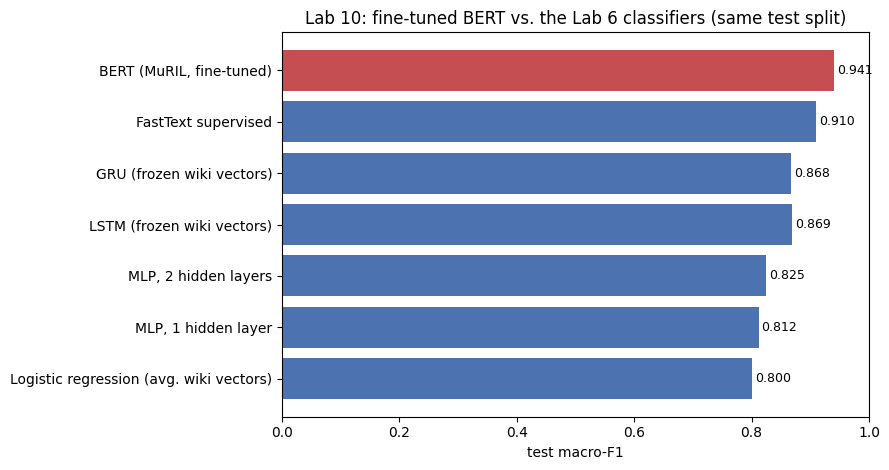

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.8))
names = [r["model"].replace(" — this lab", "") for r in rows]
vals = [r["test macro-F1"] for r in rows]
colors = ["#C44E52" if "BERT" in n else "#4C72B0" for n in names]
bars = ax.barh(names, vals, color=colors)
for b, v in zip(bars, vals):
    ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel("test macro-F1")
ax.set_title("Lab 10: fine-tuned BERT vs. the Lab 6 classifiers (same test split)")
plt.tight_layout()
plt.savefig(f"{OUT}/comparison_macro_f1.png", dpi=150)
plt.show()


### Per-language F1: BERT vs. the strongest Lab 6 models, next to the `[UNK]` rate

Each language's F1 is shown beside its MuRIL `[UNK]` rate on the test set. The `[UNK]` rate shows where the
vocabulary is the bottleneck.

In [9]:
per_lang = pd.DataFrame({
    "BERT (this lab)": {l: bert_per_class[l]["f1"] for l in labels},
    "FastText supervised": {l: lab6["fasttext_supervised"]["per_class_test"][l]["f1"] for l in labels},
    "LSTM": {l: lab6["lstm_frozen_fasttext"]["per_class_test"][l]["f1"] for l in labels},
    "Logistic regression": {l: lab6["logreg_avgvec"]["per_class_test"][l]["f1"] for l in labels},
})
per_lang["MuRIL UNK %"] = unk_df.set_index("label")["unk_pct"]
per_lang = per_lang.round(3).sort_values("BERT (this lab)")
per_lang.to_csv(f"{OUT}/per_language_f1.csv")
per_lang


,BERT (this lab),FastText supervised,LSTM,Logistic regression,MuRIL UNK %
santhali,0.699,0.943,0.715,0.674,88.09
mni_Mtei,0.731,0.964,0.674,0.093,83.14
gom_Deva,0.765,0.497,0.489,0.442,0.22
mar_Deva,0.782,0.687,0.584,0.533,0.00
brx_Deva,0.912,0.827,0.831,0.772,0.00
hin_Deva,0.919,0.772,0.794,0.614,0.05
doi_Deva,0.939,0.824,0.760,0.602,0.04
mai_Deva,0.945,0.758,0.667,0.457,0.00
khasi,0.985,0.961,0.970,0.943,0.18
san_Deva,0.985,0.838,0.785,0.683,3.62


## 7. Analysis

**Overall.** Fine-tuned MuRIL reaches test macro-F1 **0.941** (accuracy 0.941). That is the best of all the models
built in this course: 3.1 points above FastText supervised (0.910, Lab 6), and 14 points above logistic regression on
averaged vectors (0.800).

**Where BERT gains.** The gain is concentrated in the Devanagari family and close neighbours: Konkani 0.765 vs 0.497
for FastText, Marathi 0.782 vs 0.687, Hindi 0.919 vs 0.772, Maithili 0.945 vs 0.758, Sanskrit 0.985 vs 0.838, Nepali
0.995 vs 0.912. Bodo (0.912 vs 0.827) and Dogri (0.939 vs 0.824) also gain. These languages share a script and much of their vocabulary, so character patterns alone separate them
poorly. A model pretrained on Indian-language text has lexical and morphological knowledge that separates them, and
fine-tuning lets the classifier use it.

**Where BERT loses.** Santhali (Ol Chiki script, 0.699 vs 0.943 for FastText) and Manipuri (Meitei Mayek, 0.731 vs
0.964) are the two losses. MuRIL's tokenizer maps 88% and 83% of these languages' test tokens to `[UNK]`, so most of each
sentence is invisible to the model. FastText supervised learns its own character n-gram embeddings from this training
data, so it does not depend on the script being in a pretrained vocabulary. This is the coverage bottleneck found in
Lab 6, now showing up in a different model. BERT's score on these two comes from the few tokens it can see and from
sentence-level cues, not from script knowledge.

**Everything else.** Most of the remaining languages sit at 0.99–1.00 for both models, because they have distinct
scripts or distinct vocabularies, so the model choice matters little. Khasi is the exception among them: 0.985 for BERT
vs 0.961 for FastText.

**Caveats.**
- One training run with seed 42. Differences of a few tenths of a point between the strong models are within the noise
  of a single run. The 3-point overall gap and the Devanagari gains are larger than that, but seed variance was not measured.
- Three epochs, with the best epoch picked on validation macro-F1. The test set was scored once.
- The word-embedding matrix was frozen to fit the 4 GB GPU (see the note at the top). Training it would probably add
  some accuracy, and it could change the Santhali and Manipuri results.
